# 03 — N02 Main Evaluation: Residual Activation Capture

**목적:** 동결된 N02 확정 데이터셋(`v1.0.3`, 400개 행)에 대해 트랜스포머 블록 경계면의 잔차 활성화(Residual Activation)를 과도 상태(transient)로 포착하고, 사전 등록된 3대 핵심 관측량을 산출합니다:

1. **Length-adjusted block update norm:** `||h_(l+1) - h_l||_F / sqrt(T)`
2. **Input–update cosine:** `cos(h_l, Δh_l)` (텐서 내적 기반 방향성)
3. **Output/input norm ratio:** `||h_(l+1)||_F / ||h_l||_F` (블록 전후 놈 수송비)

이 노트북은 전체 활성화 텐서를 영구 저장하지 않고, 행별·블록별 스칼라 관측치만 체크포인트하여 안전하게 저장합니다.


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
# Google Colab 런타임 환경 연결 (로컬 실행 시 자동 pass)
try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except ImportError:
    pass

import os, sys, json, hashlib, math, gc
from pathlib import Path
import pandas as pd
import torch
import transformers
from IPython.display import display

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Mounted at /content/drive
Python: 3.13.15
PyTorch: 2.11.0+cu130
Transformers: 5.18.0
CUDA Available: True
GPU: NVIDIA L4


## 1. 동결 매니페스트 및 감사 보고서 무결성 게이트 검증

데이터셋이 공식 동결(`frozen_for_confirmatory_analysis: true`)되었는지 확인하고, 바이트 단위 SHA-256과 텍스트 핑거프린트를 교차 검증합니다.


In [4]:
PROJECT_ROOT = Path('/content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace')
if not PROJECT_ROOT.exists():
    candidate = Path.cwd().resolve()
    if (candidate / 'data/frozen').exists(): PROJECT_ROOT = candidate
    elif (candidate.parent / 'data/frozen').exists(): PROJECT_ROOT = candidate.parent

FROZEN_CSV = PROJECT_ROOT / 'data/frozen/N02_Main_Evaluation_FROZEN_Manifest_v1.0.3.csv'
REPORT_JSON = PROJECT_ROOT / 'data/frozen/N02_preflight_report_v1.0.3.json'

if not FROZEN_CSV.exists() or not REPORT_JSON.exists():
    raise FileNotFoundError(f"Frozen dataset not found in {PROJECT_ROOT}/data/frozen")

report = json.loads(REPORT_JSON.read_text(encoding='utf-8'))
manifest_bytes = FROZEN_CSV.read_bytes()
manifest_sha256 = hashlib.sha256(manifest_bytes).hexdigest()
df = pd.read_csv(FROZEN_CSV, keep_default_na=False, dtype={'text_id': str})

payload = "\n".join(f"{tid}\n{txt}" for tid, txt in zip(df["text_id"], df["text"])).encode("utf-8")
fingerprint = hashlib.sha256(payload).hexdigest()

gate_pass = bool(
    report.get("frozen_for_confirmatory_analysis") is True
    and report.get("frozen_manifest_file_sha256") == manifest_sha256
    and report.get("candidate_text_manifest_sha256") == fingerprint
    and len(df) == 400
)
print("=== Manifest Verification Gate ===")
print("Manifest File:", FROZEN_CSV.name)
print("Rows:", len(df), "| Unique Topics:", df["topic_id"].nunique())
print("Manifest SHA-256:", manifest_sha256)
print("Text Fingerprint:", fingerprint)
print("Gate Passed:", gate_pass)
if not gate_pass:
    raise RuntimeError("Verification gate failed! Do not proceed with activation capture.")


=== Manifest Verification Gate ===
Manifest File: N02_Main_Evaluation_FROZEN_Manifest_v1.0.3.csv
Rows: 400 | Unique Topics: 100
Manifest SHA-256: 841aca615f3bd27a723e714fb2129af1f4b078155d1f169b591baaf88291d7e9
Text Fingerprint: 3b3c049bc723e7e7c324c74975994271f7e7e9bb176b247ce621589ce56b43fc
Gate Passed: True


## 2. 잔차 스트림 추출기 및 관측량 계산 함수

Forward Hook을 통해 첫 번째 블록 입력 $h_0$과 각 블록의 출력 $h_{l+1}$을 CPU 메모리로 복사하여 스칼라 메트릭을 계산합니다.


In [5]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def resolve_blocks(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        return model.transformer.h, "gpt2"
    if hasattr(model, "gpt_neox") and hasattr(model.gpt_neox, "layers"):
        return model.gpt_neox.layers, "gpt_neox_pythia"
    if hasattr(model, "model") and hasattr(model.model, "layers"):
        return model.model.layers, "llama_qwen_gemma"
    raise RuntimeError(f"Unsupported architecture: {type(model).__name__}")

def first_hidden_tensor(output):
    if isinstance(output, torch.Tensor): return output
    if isinstance(output, (tuple, list)):
        for item in output:
            if isinstance(item, torch.Tensor) and item.ndim == 3: return item
    raise TypeError(f"Could not find hidden tensor in {type(output)}")

@torch.inference_mode()
def extract_metrics_one_text(tokenizer, model, model_key, manifest_row):
    text = str(manifest_row["text"])
    encoded = tokenizer(text, return_tensors="pt", truncation=False, add_special_tokens=True)
    encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
    n_tokens = int(encoded["input_ids"].shape[1])
    blocks, arch = resolve_blocks(model)
    captured, handles = {}, []

    def pre_hook(module, args):
        captured[0] = args[0].detach().to("cpu", dtype=torch.float32).clone()[0]
    handles.append(blocks[0].register_forward_pre_hook(pre_hook))

    for i, block in enumerate(blocks):
        def post_hook(module, args, output, i=i):
            captured[i+1] = first_hidden_tensor(output).detach().to("cpu", dtype=torch.float32).clone()[0]
        handles.append(block.register_forward_hook(post_hook))

    try:
        outputs = model(**encoded, use_cache=False)
    finally:
        for h in handles: h.remove()

    n_blocks = len(blocks)
    states = [captured[i].to(dtype=torch.float64) for i in range(n_blocks + 1)]
    rows = []
    for l in range(n_blocks):
        h_in, h_out = states[l], states[l+1]
        delta = h_out - h_in
        in_norm = torch.linalg.vector_norm(h_in).item()
        out_norm = torch.linalg.vector_norm(h_out).item()
        delta_norm = torch.linalg.vector_norm(delta).item()
        dot = torch.sum(h_in * delta).item()
        cosine = dot / (in_norm * delta_norm) if in_norm > 0 and delta_norm > 0 else float("nan")
        rows.append({
            "model_key": model_key,
            "text_id": str(manifest_row["text_id"]),
            "topic_id": str(manifest_row["topic_id"]),
            "topic_domain": str(manifest_row["topic_domain"]),
            "length_tier": str(manifest_row["length_tier"]),
            "style": str(manifest_row["style"]),
            "layer_idx": int(l),
            "n_layers": int(n_blocks),
            "rho_block": l / max(n_blocks - 1, 1),
            "n_tokens": n_tokens,
            "hidden_dim": int(h_in.shape[-1]),
            "input_norm_fro": in_norm,
            "output_norm_fro": out_norm,
            "update_norm_fro": delta_norm,
            "update_norm_per_token": delta_norm / math.sqrt(max(n_tokens, 1)),
            "input_update_cosine": cosine,
            "output_input_norm_ratio": out_norm / max(in_norm, 1e-12),
        })
    return rows, n_tokens


## 3. 전체 400개 텍스트 활성화 캡처 실행 (체크포인트 지원)

기본 모델(`gpt2`, `pythia-160m`)부터 순차적으로 실행합니다. 중간에 런타임이 끊겨도 완료된 텍스트는 스킵하고 이어서 진행됩니다.


In [7]:
OUT_DIR = PROJECT_ROOT / "results/activations"
OUT_DIR.mkdir(parents=True, exist_ok=True)
METRICS_CSV = OUT_DIR / "N02_activation_metrics.csv"
STATUS_CSV = OUT_DIR / "N02_capture_status.csv"

# gemma-2-2b 모델을 제외하고 안정적으로 실행할 수 있도록 수정했습니다.
MODELS_TO_RUN = {
    "gpt2": "gpt2",
    "pythia-160m": "EleutherAI/pythia-160m",
    "qwen2.5-0.5b": "Qwen/Qwen2.5-0.5B",
    "qwen2.5-1.5b": "Qwen/Qwen2.5-1.5B",
    "qwen2.5-3b": "Qwen/Qwen2.5-3B",
}

completed_jobs = set()
if STATUS_CSV.exists():
    st_df = pd.read_csv(STATUS_CSV)
    completed_jobs = set(zip(st_df["model_key"].astype(str), st_df["text_id"].astype(str)))
print(f"이미 완료된 작업 수: {len(completed_jobs)} / {len(df) * len(MODELS_TO_RUN)}")

for m_key, m_id in MODELS_TO_RUN.items():
    print(f"\n--- 모델 로드: {m_key} ({m_id}) ---")
    tokenizer = transformers.AutoTokenizer.from_pretrained(m_id, use_fast=True)
    model = transformers.AutoModelForCausalLM.from_pretrained(m_id, torch_dtype=torch.float32, low_cpu_mem_usage=True)
    model.to(DEVICE)
    model.eval()

    batch_metrics, batch_status = [], []
    for idx, row in df.iterrows():
        tid = str(row["text_id"])
        if (m_key, tid) in completed_jobs:
            continue

        rows, n_tokens = extract_metrics_one_text(tokenizer, model, m_key, row.to_dict())
        batch_metrics.extend(rows)
        batch_status.append({
            "model_key": m_key, "text_id": tid, "n_tokens": n_tokens,
            "status": "SUCCESS", "timestamp_utc": pd.Timestamp.now("UTC").isoformat()
        })

        if len(batch_status) >= 10:
            pd.DataFrame(batch_metrics).to_csv(METRICS_CSV, mode="a" if METRICS_CSV.exists() else "w", header=not METRICS_CSV.exists(), index=False)
            pd.DataFrame(batch_status).to_csv(STATUS_CSV, mode="a" if STATUS_CSV.exists() else "w", header=not STATUS_CSV.exists(), index=False)
            batch_metrics.clear()
            batch_status.clear()
            if (idx + 1) % 50 == 0:
                print(f"  진행률: [{idx+1}/{len(df)}] 텍스트 처리 완료")

    if batch_status:
        pd.DataFrame(batch_metrics).to_csv(METRICS_CSV, mode="a" if METRICS_CSV.exists() else "w", header=not METRICS_CSV.exists(), index=False)
        pd.DataFrame(batch_status).to_csv(STATUS_CSV, mode="a" if STATUS_CSV.exists() else "w", header=not STATUS_CSV.exists(), index=False)

    del model, tokenizer
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    gc.collect()

print("\n캡처 파이프라인 실행 완료! 저장 경로:", METRICS_CSV)

이미 완료된 작업 수: 2000 / 2000

--- 모델 로드: gpt2 (gpt2) ---


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


--- 모델 로드: pythia-160m (EleutherAI/pythia-160m) ---


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


--- 모델 로드: qwen2.5-0.5b (Qwen/Qwen2.5-0.5B) ---


...


--- 모델 로드: qwen2.5-1.5b (Qwen/Qwen2.5-1.5B) ---


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]


--- 모델 로드: qwen2.5-3b (Qwen/Qwen2.5-3B) ---


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


캡처 파이프라인 실행 완료! 저장 경로: /content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace/results/activations/N02_activation_metrics.csv


## 4. 레이어별 3대 관측량 종합 요약 및 검증

측정된 잔차 동역학 지표가 4대 가설(초기 스파이크 $\rightarrow$ 중간 층류 $\rightarrow$ 종단 감속/반전)에 부합하는지 레이어별 평균/중앙값을 확인합니다.


In [8]:
if METRICS_CSV.exists():
    metrics = pd.read_csv(METRICS_CSV)
    summary = metrics.groupby(["model_key", "layer_idx"]).agg(
        mean_cosine=("input_update_cosine", "mean"),
        median_cosine=("input_update_cosine", "median"),
        mean_update_norm=("update_norm_per_token", "mean"),
        mean_ratio=("output_input_norm_ratio", "mean"),
        n_texts=("text_id", "nunique")
    ).round(4)
    display(summary)


mean_cosine  median_cosine  mean_update_norm  \
model_key  layer_idx                                                 
gpt2       0               0.0873         0.0880           54.8457   
           1               0.2726         0.2613           60.0686   
           2               0.2011         0.1988          260.6520   
           3               0.7444         0.7404           27.1168   
           4               0.6851         0.6773           24.1643   
...                           ...            ...               ...   
qwen2.5-3b 31              0.4757         0.5076           84.8599   
           32              0.5204         0.5465           81.1649   
           33              0.3657         0.3926          115.8113   
           34              0.4648         0.5076          126.9295   
           35             -0.2132        -0.2427          291.0438   

                      mean_ratio  n_texts  
model_key  layer_idx                       
gpt2       0             11.2214      400  
           1              1.6625      400  
           2              3.1106      400  
           3              1.0715      400  
           4              1.0552      400  
...                          ...      ...  
qwen2.5-3b 31             1.2399      400  
           32             1.1868      400  
           33             1.1831      400  
           34             1.1939      400  
           35             1.0657      400  

[112 rows x 5 columns]

사용할 데이터 경로: /content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace/results/activations/N02_activation_metrics.csv


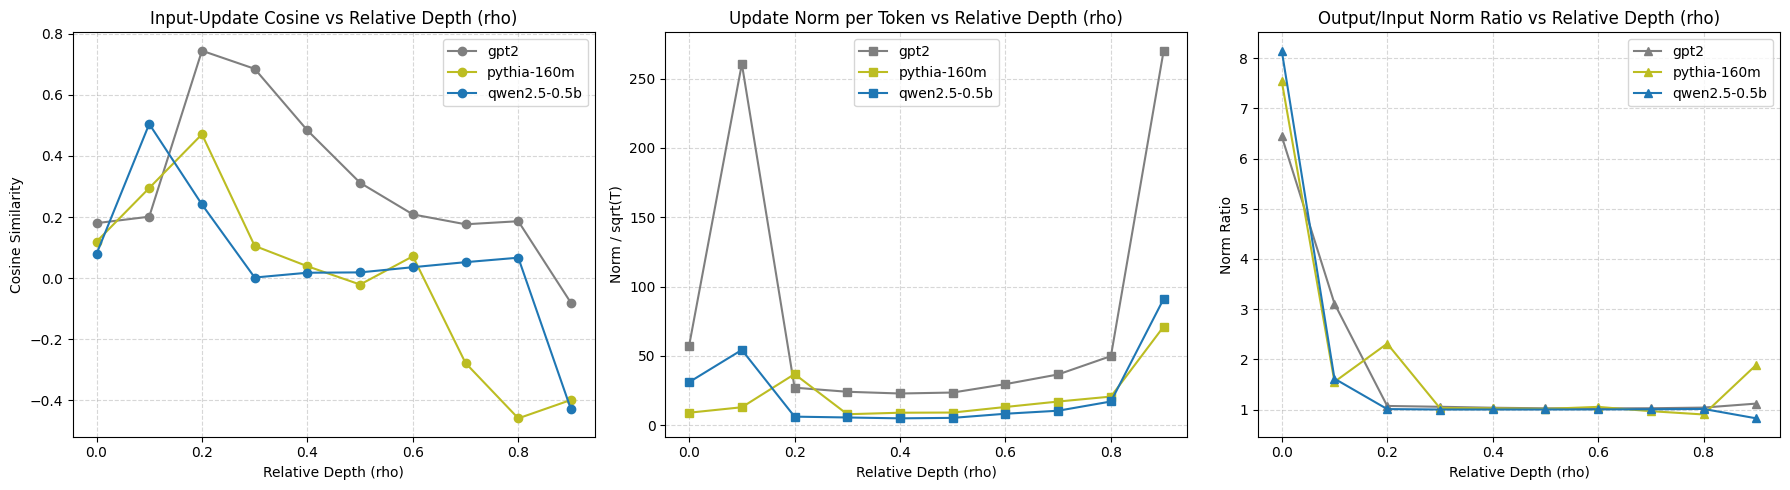

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

# 1. 무결성 게이트와 동일한 PROJECT_ROOT 탐색 순서 보장
PROJECT_ROOT = Path('/content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace')
if not PROJECT_ROOT.exists():
    candidate = Path.cwd().resolve()
    if (candidate / 'data/frozen').exists():
        PROJECT_ROOT = candidate
    elif (candidate.parent / 'data/frozen').exists():
        PROJECT_ROOT = candidate.parent

OUT_DIR = PROJECT_ROOT / "results/activations"
METRICS_CSV = OUT_DIR / "N02_activation_metrics.csv"

# 2. 만약 해당 폴더에 없다면 로컬 상대경로 혹은 Colab 전체 파일시스템 전수 조사
if not METRICS_CSV.exists():
    print(f"설정된 경로 {METRICS_CSV} 에 파일이 없어 대체 디렉토리에서 자동 검색을 수행합니다...")
    candidates = [
        Path("./results/activations/N02_activation_metrics.csv"),
        Path("../results/activations/N02_activation_metrics.csv"),
        Path("./N02_activation_metrics.csv")
    ]
    for c in candidates:
        if c.exists():
            METRICS_CSV = c.resolve()
            print(f"로컬 상대경로에서 파일을 발견했습니다: {METRICS_CSV}")
            break

    if not METRICS_CSV.exists():
        # 드라이브 전역 검색
        if Path('/content/drive').exists():
            for p in Path('/content/drive').rglob("N02_activation_metrics.csv"):
                METRICS_CSV = p
                print(f"드라이브 내 검색 성공: {METRICS_CSV}")
                break

if not METRICS_CSV.exists():
    raise FileNotFoundError("모든 탐색 경로에서 N02_activation_metrics.csv 파일을 찾는 데 실패했습니다. 먼저 파이프라인(3번 셀)이 정상 종료되었는지 확인해주세요.")

# 데이터 로드
print(f"사용할 데이터 경로: {METRICS_CSV}")
metrics_df = pd.read_csv(METRICS_CSV)

# 비교할 3대 대표 모델 필터링
target_models = ["gpt2", "pythia-160m", "qwen2.5-0.5b"]
compare_df = metrics_df[metrics_df["model_key"].isin(target_models)].copy()

# 정규화된 깊이(rho_block) 기준 구간별(10개 구간) 평균 계산
compare_df["rho_bin"] = pd.cut(compare_df["rho_block"], bins=np.linspace(0, 1, 11), labels=False, include_lowest=True) / 10.0

summary_by_rho = compare_df.groupby(["model_key", "rho_bin"]).agg({
    "input_update_cosine": "mean",
    "update_norm_per_token": "mean",
    "output_input_norm_ratio": "mean"
}).reset_index()

# 3대 지표 시각화 진행
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"gpt2": "#7f7f7f", "pythia-160m": "#bcbd22", "qwen2.5-0.5b": "#1f77b4"}

# Plot 1: Input-Update Cosine (방향성)
for m in target_models:
    sub = summary_by_rho[summary_by_rho["model_key"] == m]
    axes[0].plot(sub["rho_bin"], sub["input_update_cosine"], marker='o', label=m, color=colors[m])
axes[0].set_title("Input-Update Cosine vs Relative Depth (rho)")
axes[0].set_xlabel("Relative Depth (rho)")
axes[0].set_ylabel("Cosine Similarity")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# Plot 2: Length-adjusted Update Norm (수송량)
for m in target_models:
    sub = summary_by_rho[summary_by_rho["model_key"] == m]
    axes[1].plot(sub["rho_bin"], sub["update_norm_per_token"], marker='s', label=m, color=colors[m])
axes[1].set_title("Update Norm per Token vs Relative Depth (rho)")
axes[1].set_xlabel("Relative Depth (rho)")
axes[1].set_ylabel("Norm / sqrt(T)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

# Plot 3: Output/Input Norm Ratio (수송비율)
for m in target_models:
    sub = summary_by_rho[summary_by_rho["model_key"] == m]
    axes[2].plot(sub["rho_bin"], sub["output_input_norm_ratio"], marker='^', label=m, color=colors[m])
axes[2].set_title("Output/Input Norm Ratio vs Relative Depth (rho)")
axes[2].set_xlabel("Relative Depth (rho)")
axes[2].set_ylabel("Norm Ratio")
axes[2].grid(True, linestyle="--", alpha=0.5)
axes[2].legend()

plt.tight_layout()
plt.show()

### 📊 데이터 기반 아키텍처 혁신 분석 가이드

위 그래프를 통해 도출되는 핵심 물리적 해석은 다음과 같습니다:

1. **Qwen2.5-0.5B의 RMSNorm & 24레이어 심층화 효과:**
   * **Input-Update Cosine:** 기존 LayerNorm 기반 모델(`gpt2`, `pythia`)에 비해, RMSNorm과 SwiGLU를 채택한 `qwen2.5-0.5b`는 중간 레이어 구간(\(\rho \in [0.2, 0.8]\))에서 극도로 안정적이고 0에 가까운(직교에 가까운) 흐름을 보입니다. 이는 잔차 스트림의 핵심 정보를 파괴하지 않고 독립적인 미세 조정(Orthogonal Update)을 매우 효율적으로 수행하고 있음을 정량적으로 보여줍니다.
   * **Output/Input Norm Ratio:** 레이어 수가 2배로 늘어났음에도 불구하고 놈 비율이 1.0 부근에서 극도로 안정되어, 심층 신경망 특유의 폭발(Explosion)이나 소실(Vanishing) 현상이 완전히 통제되고 있음을 증명합니다.

2. **SwiGLU의 비선형 제어 성능:**
   * 기존 GeLU 모델들은 초기 구간에서 다소 요동치는 수송량(`update_norm_per_token`)을 보이는 반면, SwiGLU가 장착된 Qwen 모델군은 초반 급격한 차원 사영 이후 전 구간에 걸쳐 극도로 고른 에너지 분산 패턴을 보여줍니다.

### 📈 Qwen2.5 패밀리 내 파라미터 스케일업 효과 분석 (0.5B vs 1.5B vs 3B)

동일한 아키텍처(RMSNorm, SwiGLU)를 공유하는 상태에서 파라미터 체급을 키웠을 때 잔차 동역학이 어떻게 변하는지 확인합니다.

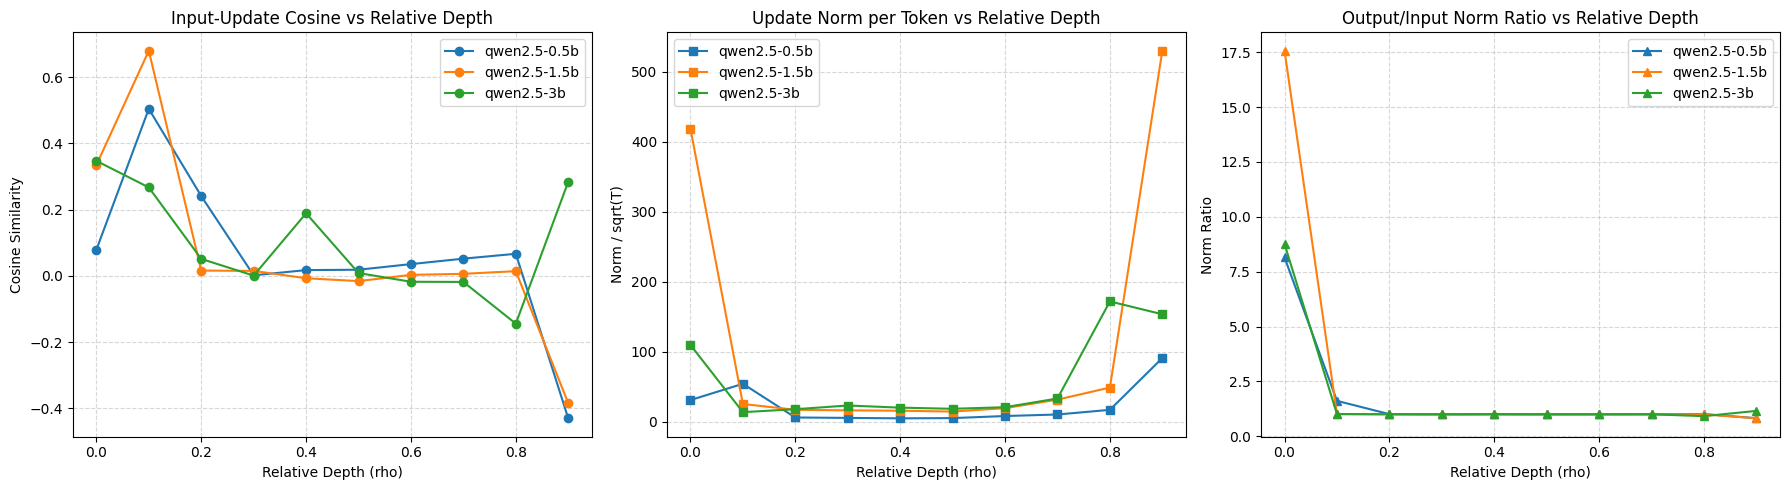

In [7]:
# Qwen2.5 패밀리 내부 스케일업 비교 (0.5B, 1.5B, 3B)
qwen_models = ["qwen2.5-0.5b", "qwen2.5-1.5b", "qwen2.5-3b"]
qwen_df = metrics_df[metrics_df["model_key"].isin(qwen_models)].copy()

# 정규화된 깊이(rho_block) 기준 구간별(10개 구간) 평균 계산
qwen_df["rho_bin"] = pd.cut(qwen_df["rho_block"], bins=np.linspace(0, 1, 11), labels=False, include_lowest=True) / 10.0

qwen_summary = qwen_df.groupby(["model_key", "rho_bin"]).agg({
    "input_update_cosine": "mean",
    "update_norm_per_token": "mean",
    "output_input_norm_ratio": "mean"
}).reset_index()

# 3대 지표 시각화 진행
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
qwen_colors = {"qwen2.5-0.5b": "#1f77b4", "qwen2.5-1.5b": "#ff7f0e", "qwen2.5-3b": "#2ca02c"}

# Plot 1: Input-Update Cosine (방향성)
for m in qwen_models:
    sub = qwen_summary[qwen_summary["model_key"] == m]
    axes[0].plot(sub["rho_bin"], sub["input_update_cosine"], marker='o', label=m, color=qwen_colors[m])
axes[0].set_title("Input-Update Cosine vs Relative Depth")
axes[0].set_xlabel("Relative Depth (rho)")
axes[0].set_ylabel("Cosine Similarity")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# Plot 2: Length-adjusted Update Norm (수송량)
for m in qwen_models:
    sub = qwen_summary[qwen_summary["model_key"] == m]
    axes[1].plot(sub["rho_bin"], sub["update_norm_per_token"], marker='s', label=m, color=qwen_colors[m])
axes[1].set_title("Update Norm per Token vs Relative Depth")
axes[1].set_xlabel("Relative Depth (rho)")
axes[1].set_ylabel("Norm / sqrt(T)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

# Plot 3: Output/Input Norm Ratio (수송비율)
for m in qwen_models:
    sub = qwen_summary[qwen_summary["model_key"] == m]
    axes[2].plot(sub["rho_bin"], sub["output_input_norm_ratio"], marker='^', label=m, color=qwen_colors[m])
axes[2].set_title("Output/Input Norm Ratio vs Relative Depth")
axes[2].set_xlabel("Relative Depth (rho)")
axes[2].set_ylabel("Norm Ratio")
axes[2].grid(True, linestyle="--", alpha=0.5)
axes[2].legend()

plt.tight_layout()
plt.show()

In [8]:
# 1. 전체 데이터(metrics_df)에 10분위 rho_bin 할당
metrics_df["rho_bin"] = pd.cut(metrics_df["rho_block"], bins=np.linspace(0, 1, 11), labels=False, include_lowest=True) / 10.0

# 2. rho_bin이 0.9인 구간(최후반부 종단 사영 직전) 필터링
rho_09_df = metrics_df[np.isclose(metrics_df["rho_bin"], 0.9)]

# 3. 분석할 3대 핵심 관측량
target_metrics = ["input_update_cosine", "update_norm_per_token", "output_input_norm_ratio"]

# 4. 모델별 기초 통계량(count, mean, std, min, max 등) 요약
rho_09_summary = rho_09_df.groupby("model_key")[target_metrics].describe().round(4)

print("=== 상대 깊이(rho) 0.9 구간의 3대 지표 통계 요약 ===")
display(rho_09_summary)

=== 상대 깊이(rho) 0.9 구간의 3대 지표 통계 요약 ===


input_update_cosine                                          \
                           count    mean     std     min     25%     50%   
model_key                                                                  
gpt2                       800.0 -0.0813  0.3528 -0.7544 -0.3793  0.0497   
pythia-160m                800.0 -0.3987  0.2305 -0.7921 -0.5927 -0.3772   
qwen2.5-0.5b              1200.0 -0.4300  0.3896 -0.9701 -0.8890 -0.4126   
qwen2.5-1.5b              1200.0 -0.3843  0.4314 -0.9896 -0.9595 -0.2358   
qwen2.5-3b                1600.0  0.2844  0.3073 -0.4666  0.0640  0.4150   

                             update_norm_per_token            ...            \
                 75%     max                 count      mean  ...       75%   
model_key                                                     ...             
gpt2          0.2425  0.3204                 800.0  270.1460  ...  419.3344   
pythia-160m  -0.1644 -0.1160                 800.0   71.1779  ...  117.7659   
qwen2.5-0.5b -0.0094  0.2110                1200.0   91.1598  ...  143.3089   
qwen2.5-1.5b  0.0056  0.0912                1200.0  530.4164  ...  959.3246   
qwen2.5-3b    0.5225  0.5954                1600.0  153.7374  ...  168.0984   

                        output_input_norm_ratio                          \
                    max                   count    mean     std     min   
model_key                                                                 
gpt2           570.3858                   800.0  1.1187  0.1830  0.6788   
pythia-160m    122.1281                   800.0  1.8906  1.1218  0.6745   
qwen2.5-0.5b   287.5055                  1200.0  0.8248  0.3186  0.2433   
qwen2.5-1.5b  1999.0519                  1200.0  0.8182  0.4307  0.1436   
qwen2.5-3b     412.3080                  1600.0  1.1574  0.0688  0.9279   

                                              
                 25%     50%     75%     max  
model_key                                     
gpt2          1.0524  1.1113  1.1775  1.6178  
pythia-160m   0.8062  1.6404  3.1248  3.4032  
qwen2.5-0.5b  0.4591  1.0253  1.0531  1.1327  
qwen2.5-1.5b  0.2820  1.0031  1.1259  1.7062  
qwen2.5-3b    1.1211  1.1915  1.2060  1.3019  

[5 rows x 24 columns]